In [1]:
import tensorflow as tf
from transformers import RobertaTokenizer, TFRobertaForSequenceClassification
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
import re
def load_data(file_path):
    return pd.read_csv(file_path, delimiter=';', header=None, names=['text', 'label'])

# Load datasets
train_data = load_data('/content/train.txt')
val_data = load_data('/content/val.txt')
test_data = load_data('/content/test.txt')

# Clean text and encode labels
def clean_text(text):
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'[^\w\s]', '', text)  # Remove punctuation
    return text



In [3]:
train_data['text'] = train_data['text'].apply(clean_text)
val_data['text'] = val_data['text'].apply(clean_text)
test_data['text'] = test_data['text'].apply(clean_text)



In [4]:
label_encoder = LabelEncoder()
train_data['label'] = label_encoder.fit_transform(train_data['label'])
val_data['label'] = label_encoder.transform(val_data['label'])
test_data['label'] = label_encoder.transform(test_data['label'])


In [5]:
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

def tokenize_and_encode(sentences, max_len=128):
    return tokenizer(sentences, padding=True, truncation=True, max_length=max_len, return_tensors="tf")

train_encodings = tokenize_and_encode(train_data['text'].tolist())
val_encodings = tokenize_and_encode(val_data['text'].tolist())
test_encodings = tokenize_and_encode(test_data['text'].tolist())


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

In [6]:
model = TFRobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=len(label_encoder.classes_))

# Compile the model
optimizer = tf.keras.optimizers.Adam(learning_rate=5e-5)
loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

# Train the model
train_dataset = tf.data.Dataset.from_tensor_slices((dict(train_encodings), train_data['label'])).batch(32)
val_dataset = tf.data.Dataset.from_tensor_slices((dict(val_encodings), val_data['label'])).batch(32)

history = model.fit(train_dataset, epochs=20, validation_data=val_dataset)


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFRobertaForSequenceClassification: ['roberta.embeddings.position_ids']
- This IS expected if you are initializing TFRobertaForSequenceClassification from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFRobertaForSequenceClassification from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
Some weights or buffers of the TF 2.0 model TFRobertaForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['classifier.dense.weight', 'classifier.dense.bias', 'classifier.out_proj.weight', 'classifier.out_proj.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predicti

Epoch 1/20


Cause: for/else statement not yet supported
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: for/else statement not yet supported
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
500/500 [==============================] - 419s 639ms/step - loss: 0.6131 - accuracy: 0.7920 - val_loss: 0.3196 - val_accuracy: 0.9110
Epoch 2/20
500/500 [==============================] - 301s 602ms/step - loss: 0.2142 - accuracy: 0.9220 - val_loss: 0.1546 - val_accuracy: 0.9400
Epoch 3/20
500/500 [==============================] - 301s 602ms/step - loss: 0.1709 - accuracy: 0.9307 - val_loss: 0.1359 - val_accuracy: 0.9405
Epoch 4/20
500/500 [==============================] - 300s 600ms/step - loss: 0.1441 - accuracy: 0.9378 - val_loss: 0.1269 - val_accuracy: 0.9425
Epoch 5/20
500/500 [==============================] - 301s 602ms/step - loss: 0.1284 - accuracy: 0.9400 - val_loss: 0.1515 - val_accuracy: 0.9380
Epoch 6/20
500/500 [==============================] - 301s 602ms/step - loss: 0.1306 - accuracy: 0.9396 - val_loss: 0.1782 - val_accuracy: 0.92

In [7]:
model.save_pretrained('/content/drive/MyDrive/new_emotions/model_roberta_A')
tokenizer.save_pretrained('/content/drive/MyDrive/new_emotions/model_roberta_A')


('/content/drive/MyDrive/new_emotions/model_roberta_A/tokenizer_config.json',
 '/content/drive/MyDrive/new_emotions/model_roberta_A/special_tokens_map.json',
 '/content/drive/MyDrive/new_emotions/model_roberta_A/vocab.json',
 '/content/drive/MyDrive/new_emotions/model_roberta_A/merges.txt',
 '/content/drive/MyDrive/new_emotions/model_roberta_A/added_tokens.json')

In [8]:
model.summary()

Model: "tf_roberta_for_sequence_classification"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 roberta (TFRobertaMainLaye  multiple                  124055040 
 r)                                                              
                                                                 
 classifier (TFRobertaClass  multiple                  595206    
 ificationHead)                                                  
                                                                 
Total params: 124650246 (475.50 MB)
Trainable params: 124650246 (475.50 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [9]:
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support

# Assuming 'test_encodings' and 'test_data' are already prepared and available

test_dataset = tf.data.Dataset.from_tensor_slices((dict(test_encodings), test_data['label'])).batch(32)

# Get predictions for the test set
y_pred = model.predict(test_dataset)
y_pred_labels = np.argmax(y_pred.logits, axis=1)

# True labels
y_true = test_data['label'].values



63/63 [==============================] - 39s 153ms/step


In [10]:

# Calculate and print the classification metrics
print(classification_report(y_true, y_pred_labels))
print("Accuracy:", accuracy_score(y_true, y_pred_labels))

              precision    recall  f1-score   support

           0       0.92      0.95      0.93       275
           1       0.87      0.95      0.91       224
           2       0.95      0.95      0.95       695
           3       0.84      0.78      0.81       159
           4       0.97      0.97      0.97       581
           5       0.90      0.67      0.77        66

    accuracy                           0.93      2000
   macro avg       0.91      0.88      0.89      2000
weighted avg       0.93      0.93      0.93      2000

Accuracy: 0.9315


In [13]:
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support

# Assuming 'test_encodings' and 'test_data' are already prepared and available
test_dataset = tf.data.Dataset.from_tensor_slices((dict(test_encodings), test_data['label'])).batch(32)

# Get predictions for the test set
y_pred = model.predict(test_dataset)
y_pred_labels = np.argmax(y_pred.logits, axis=1)

# True labels
y_true = test_data['label'].values

# Calculate metrics
report = classification_report(y_true, y_pred_labels, target_names=label_encoder.classes_)

print("Classification Report:")
print(report)

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred_labels)
print("Accuracy:", accuracy)

# Other metrics such as F1, Precision, Recall
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred_labels, average='weighted')
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


63/63 [==============================] - 9s 140ms/step
Classification Report:
              precision    recall  f1-score   support

       anger       0.92      0.95      0.93       275
        fear       0.87      0.95      0.91       224
         joy       0.95      0.95      0.95       695
        love       0.84      0.78      0.81       159
     sadness       0.97      0.97      0.97       581
    surprise       0.90      0.67      0.77        66

    accuracy                           0.93      2000
   macro avg       0.91      0.88      0.89      2000
weighted avg       0.93      0.93      0.93      2000

Accuracy: 0.9315
Precision: 0.9313126062408366
Recall: 0.9315
F1 Score: 0.9305215774901531


In [14]:
import pandas as pd

# Creating a DataFrame for pretty display
metrics_df = pd.DataFrame({
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1 Score": [f1]
})

print("Metrics Summary:")
print(metrics_df)


Metrics Summary:
   Accuracy  Precision  Recall  F1 Score
0    0.9315   0.931313  0.9315  0.930522


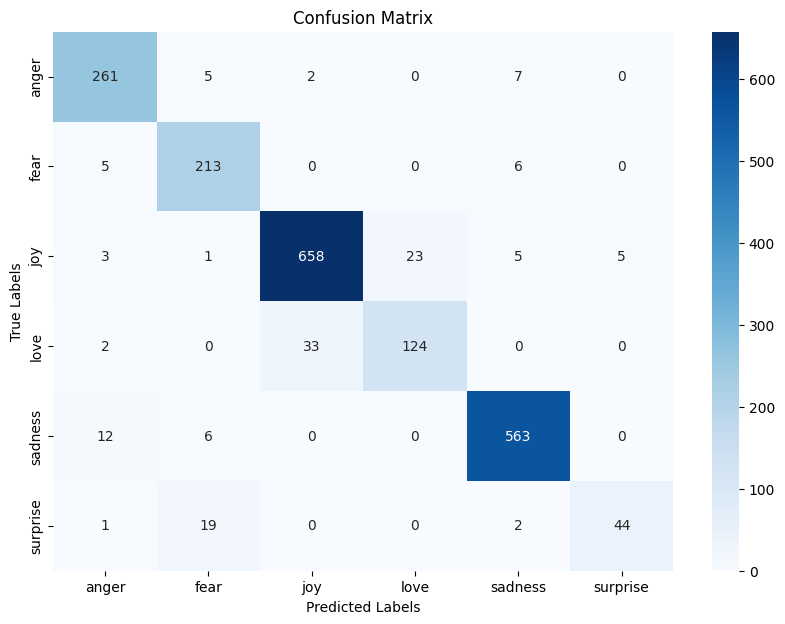

In [15]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns  # For better visualization of confusion matrices
# Assuming y_pred_labels and y_true are defined from previous steps

# Compute the confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_labels)
# Define labels if necessary; adjust according to your dataset
labels = label_encoder.classes_

# Plotting the confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()
